# Day 28 / 100 — BoxCount Vision | Master Kaggle Notebook

**Research scope:** single-class box detection (`class 0`) and counting on two distinct source domains. **Not** industrial inventory verification or safety monitoring. Data source: `/kaggle/input/datasets/wafabila/boxcount-vision-dataset`.

**Experimental sequence:** Dataset manifest → integrity / leakage checks → visual audit → Experiment A (Cardboard v5) → external-domain evaluation on Logistics → optional Experiment B (controlled mixed-domain training) → final held-out evaluation → counting error analysis → exports. Training and results are computed **only when cells execute**.

**Critical design:** source datasets remain isolated, no random re-split, no test-based hyperparameter search; use validation to choose the champion; run held-out test last. Existing SHA-256 dedup removes known exact cross-split copies, but near-duplicates and sequence leakage remain unverified. The Logistics source has many negative-only images and potential annotation incompleteness; visual inspections are mandatory.

## 00 — Environment and experiment switches

In [1]:
import os, sys, subprocess, importlib.util
from pathlib import Path
print('Python',sys.version)
print('Kaggle input exists:',Path('/kaggle/input').exists())
if importlib.util.find_spec('ultralytics') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics>=8.3,<9'])
import ultralytics
ultralytics.checks()

Ultralytics 8.4.194 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7108.1/8156.9 GB disk)


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import os, json, hashlib, math, random, shutil, csv, warnings, gc
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch, yaml
from ultralytics import YOLO

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
INPUT_ROOT=Path('/kaggle/input/datasets/wafabila/boxcount-vision-dataset')
# Kaggle sometimes changes the mounted path; explicit root first, recursive discovery second.
if not INPUT_ROOT.exists():
    candidates=list(Path('/kaggle/input').rglob('filename_audit.json'))
    if not candidates: raise FileNotFoundError('Input root not found. Attach BoxCount Vision dataset to this notebook.')
    INPUT_ROOT=candidates[0].parent
WORK=Path('/kaggle/working/boxcount_day28'); WORK.mkdir(parents=True,exist_ok=True)
OUT=WORK/'artifacts';OUT.mkdir(exist_ok=True)
DATASETS=['cardboard_v5','logistics_v10']; SPLITS=['train','valid','test']
# Set to True only for experiments you want to execute. Budget-aware defaults.
RUN_EXPERIMENT_A=True
RUN_EXTERNAL_EVAL=True
RUN_EXPERIMENT_B=False   # optional costly mixed-domain run
RUN_FINAL_TEST=True
RUN_NEAR_DUP_SAMPLE=True
BASE_WEIGHTS='yolov8n.pt'  # practical Kaggle baseline; no pretrained-performance claim
EPOCHS_A=15; EPOCHS_B=15; IMGSZ=640; BATCH=16
TRAIN_POS_LIMIT=5000; TRAIN_NEG_LIMIT=1500
VAL_POS_LIMIT=1000; VAL_NEG_LIMIT=350
# The source test split is NEVER used to select a model.
DEVICE=0 if torch.cuda.is_available() else 'cpu'
print('Input root:',INPUT_ROOT,'GPU:',torch.cuda.is_available(),'Device:',DEVICE)
print('Available items:',[p.name for p in INPUT_ROOT.iterdir()][:15])

Input root: /kaggle/input/datasets/wafabila/boxcount-vision-dataset GPU: True Device: 0
Available items: ['cardboard_v5', 'dataset_audit_clean.json', 'filename_audit.json', 'filename_mapping.csv', 'logistics_v10']


## 01 — Locate the two independent datasets and record provenance

In [3]:
def locate_dataset(root,name):
    options=[root/name]+[p for p in root.rglob(name) if p.is_dir()]
    for p in options:
        if (p/'train'/'images').is_dir() and (p/'train'/'labels').is_dir():return p
    raise FileNotFoundError(f'{name} with train/images and train/labels not found under {root}')
SRC={name:locate_dataset(INPUT_ROOT,name) for name in DATASETS}
for name,p in SRC.items(): print(name,'=>',p)
for filename in ('dataset_audit_clean.json','filename_audit.json'):
    files=list(INPUT_ROOT.rglob(filename))
    if files:
        obj=json.loads(files[0].read_text(encoding='utf-8-sig'))
        print(filename, 'keys:',list(obj)[:18])
        (OUT/filename).write_text(json.dumps(obj,indent=2,ensure_ascii=False),encoding='utf-8')

cardboard_v5 => /kaggle/input/datasets/wafabila/boxcount-vision-dataset/cardboard_v5
logistics_v10 => /kaggle/input/datasets/wafabila/boxcount-vision-dataset/logistics_v10
dataset_audit_clean.json keys: ['project', 'source_zip', 'output_zip', 'method', 'split_priority', 'total_input_images', 'duplicate_hash_groups', 'cross_split_hash_groups', 'conflicting_annotation_groups', 'removed_from_lower_priority_splits', 'removal_examples', 'conflicts', 'before', 'limitations', 'after', 'status']
filename_audit.json keys: ['status', 'source', 'total_image_label_pairs', 'images_per_split', 'filename_policy', 'original_filenames_preserved_in', 'original_archive_unchanged', 'original_split_assignments_unchanged', 'annotations_unchanged']


## 02 — Audit image/label pairs, numeric bounds, and class contract

In [4]:
IMAGE_SUFFIX={'.jpg','.jpeg','.png','.webp'}
def audit_pair(img,label):
    errors=[];count=0
    try:
        with Image.open(img) as im:
            if im.width<2 or im.height<2:errors.append('tiny_image')
            im.verify()
    except Exception as ex:errors.append('invalid_image:'+type(ex).__name__)
    try:
        for i,line in enumerate(label.read_text(encoding='utf-8-sig').splitlines(),1):
            if not line.strip():continue
            items=line.split()
            if len(items)!=5:errors.append(f'line_{i}_fields');continue
            c=float(items[0]);coords=list(map(float,items[1:]))
            if c!=0 or not all(math.isfinite(v) for v in coords):errors.append(f'line_{i}_class_or_nan');continue
            x,y,w,h=coords
            if not(0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1 and x-w/2>=-1e-5 and x+w/2<=1+1e-5 and y-h/2>=-1e-5 and y+h/2<=1+1e-5):errors.append(f'line_{i}_bbox')
            count+=1
    except Exception as ex:errors.append('invalid_label:'+type(ex).__name__)
    return count,errors

records=[]; failures=[]
for dataset,root in SRC.items():
    for split in SPLITS:
        ip=root/split/'images';lp=root/split/'labels'
        if not ip.exists() or not lp.exists():raise FileNotFoundError(f'{dataset}/{split}: missing folder')
        images=sorted(x for x in ip.iterdir() if x.is_file() and x.suffix.lower() in IMAGE_SUFFIX)
        labels={x.stem:x for x in lp.glob('*.txt')}
        image_stems=[x.stem for x in images]
        if len(image_stems)!=len(set(image_stems)):raise AssertionError(f'Duplicate image stems: {dataset}/{split}')
        if set(image_stems)!=set(labels):raise AssertionError(f'Mismatched image/label: {dataset}/{split}; missing={len(set(image_stems)-set(labels))}, orphan={len(set(labels)-set(image_stems))}')
        for idx,img in enumerate(images):
            n,errors=audit_pair(img,labels[img.stem])
            records.append(dict(dataset=dataset,split=split,image=str(img),label=str(labels[img.stem]),boxes=n,positive=n>0))
            if errors:failures.append(dict(image=str(img),errors=';'.join(errors)))
        print(dataset,split, 'images:',len(images))
manifest=pd.DataFrame(records);summary=manifest.groupby(['dataset','split']).agg(images=('image','size'),positive=('positive','sum'),boxes=('boxes','sum')).reset_index()
summary['negative']=summary.images-summary.positive
print(summary.to_string(index=False));print('Invalid pairs:',len(failures))
summary.to_csv(OUT/'dataset_inventory.csv',index=False)
pd.DataFrame(failures,columns=['image','errors']).to_csv(OUT/'invalid_annotation_audit.csv',index=False)
if failures: raise RuntimeError('Annotation audit failed; inspect invalid_annotation_audit.csv before training')

cardboard_v5 train images: 8403
cardboard_v5 valid images: 539
cardboard_v5 test images: 274
logistics_v10 train images: 69616
logistics_v10 valid images: 19831
logistics_v10 test images: 9936
      dataset split  images  positive  boxes  negative
 cardboard_v5  test     274       274   2644         0
 cardboard_v5 train    8403      8403 143331         0
 cardboard_v5 valid     539       539   9274         0
logistics_v10  test    9936       449   5060      9487
logistics_v10 train   69616      3128  34529     66488
logistics_v10 valid   19831       867   9946     18964
Invalid pairs: 0


## 03 — Detect exact SHA-256 overlap and sample perceptual-hash near-duplicates

In [5]:
def sha_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
# Repeat exact-leakage check on mounted data rather than trusting prior local audit.
sha_map=defaultdict(list)
for i,row in enumerate(manifest.itertuples(index=False)):
    sha_map[sha_file(row.image)].append((row.dataset,row.split,row.image))
    if (i+1)%20000==0:print('SHA:',i+1)
exact=[v for v in sha_map.values() if len({x[1] for x in v})>1]
print('Exact cross-split image hash groups:',len(exact))
(OUT/'sha_leakage_audit.json').write_text(json.dumps({'groups':len(exact),'examples':exact[:30]},indent=2),encoding='utf-8')
if exact:raise RuntimeError('Exact cross-split duplicate images detected; stop before training')

SHA: 20000
SHA: 40000
SHA: 60000
SHA: 80000
SHA: 100000
Exact cross-split image hash groups: 0


In [6]:
# Cheap approximate check: dHash on a capped, deterministic sample.
# This is NOT an exhaustive near-duplicate or source/video grouping audit.
def dhash(path):
    with Image.open(path) as im:
        g=im.convert('L').resize((9,8))
        a=np.asarray(g,dtype=np.uint8)
    bits=(a[:,1:]>a[:,:-1]).reshape(-1)
    return sum(int(v)<<i for i,v in enumerate(bits))
near=[]
if RUN_NEAR_DUP_SAMPLE:
    sample=manifest.groupby(['dataset','split'],group_keys=False).apply(lambda d:d.sample(n=min(350,len(d)),random_state=SEED),include_groups=False).reset_index(drop=True)
    hashes=[]
    for row in sample.itertuples(index=False):
        try:hashes.append((row.dataset,row.split,row.image,dhash(row.image)))
        except Exception:pass
    for i,a in enumerate(hashes):
        for b in hashes[i+1:]:
            if a[1]==b[1]:continue
            dist=(a[3]^b[3]).bit_count()
            if dist<=4:
                near.append({'a':a[2],'b':b[2],'distance':dist})
    print('Sample near-duplicate candidates (manual review):',len(near))
    pd.DataFrame(near,columns=['a','b','distance']).to_csv(OUT/'near_duplicate_candidates_sample.csv',index=False)
    if near: print('WARNING: possible cross-split near-duplicates. Review candidates and source-level leakage before trusting test metrics.')

Sample near-duplicate candidates (manual review): 0


## 04 — Visualization: random positive and negative images with boxes

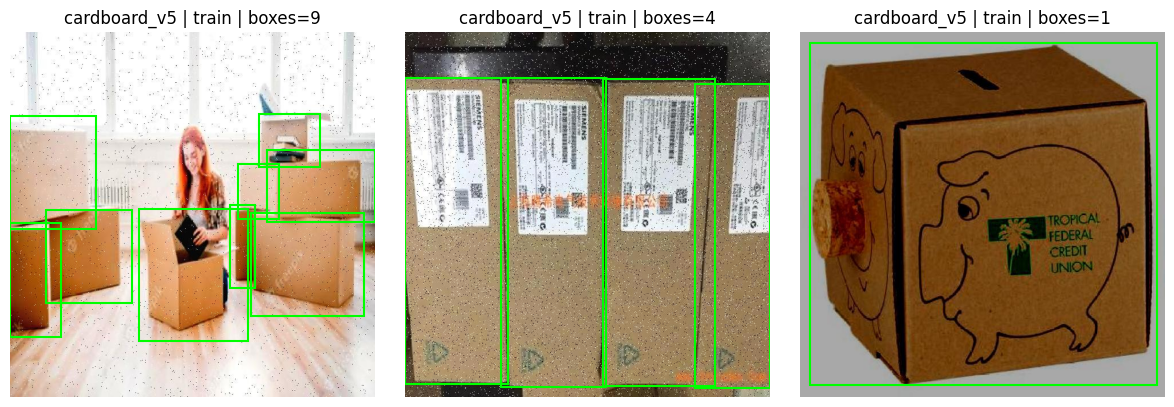

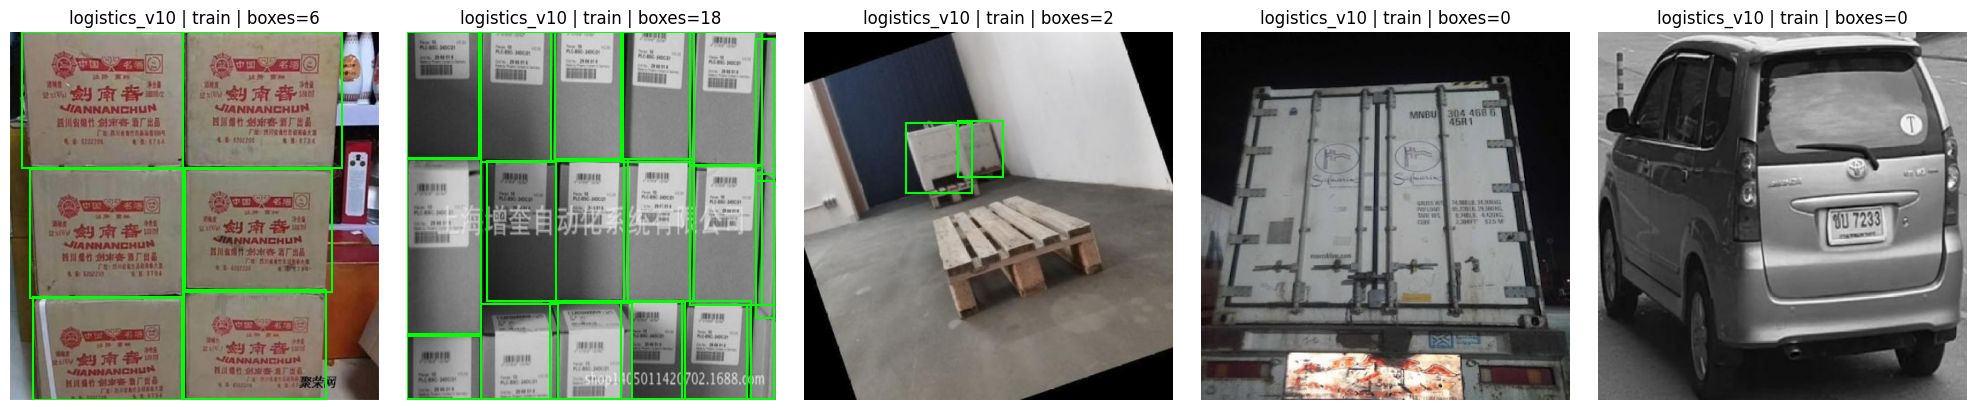

In [7]:
def render_label(ax, image_path, label_path):
    with Image.open(image_path) as im: pic=im.convert('RGB')
    ax.imshow(pic);W,H=pic.size
    for line in Path(label_path).read_text(encoding='utf-8-sig').splitlines():
        if not line.strip():continue
        cls,x,y,w,h=map(float,line.split())
        x0=(x-w/2)*W;y0=(y-h/2)*H
        from matplotlib.patches import Rectangle
        ax.add_patch(Rectangle((x0,y0),w*W,h*H,linewidth=1.5,edgecolor='lime',facecolor='none'))
    ax.axis('off')

for dataset in DATASETS:
    sub=manifest[(manifest.dataset==dataset)&(manifest.split=='train')]
    samples=pd.concat([sub[sub.positive].sample(n=min(3,int(sub.positive.sum())),random_state=SEED),sub[~sub.positive].sample(n=min(2,int((~sub.positive).sum())),random_state=SEED)])
    if samples.empty:continue
    fig,axes=plt.subplots(1,len(samples),figsize=(4*len(samples),4),squeeze=False)
    for ax,row in zip(axes[0],samples.itertuples(index=False)):
        render_label(ax,row.image,row.label)
        ax.set_title(f'{dataset} | {row.split} | boxes={row.boxes}')
    fig.tight_layout();fig.savefig(OUT/f'{dataset}_annotation_gallery.png',dpi=130,bbox_inches='tight');plt.show()

## 05 — Construct a controlled, bounded research subset (source-aware, deterministic)

The Logistics domain is dominated by negative-only images. To avoid swamping the baseline, we cap negatives and positives **within each source/split**. We do **not** rebalance or alter the original held-out test set for final reporting. To preserve the strict no-test-tuning contract, any analysis of test images/labels above is structural QA only—not performance-based model selection. The mixed-domain experiment is optional. The selected sampled train/validation manifests are saved for reproducibility.

In [8]:
def sampled_source(dataset,split,pos_limit,neg_limit):
    rows=manifest[(manifest.dataset==dataset)&(manifest.split==split)]
    if split=='test':return rows.copy()
    pos=rows[rows.positive];neg=rows[~rows.positive]
    p=pos.sample(n=min(pos_limit,len(pos)),random_state=SEED) if len(pos)>pos_limit else pos
    q=neg.sample(n=min(neg_limit,len(neg)),random_state=SEED) if len(neg)>neg_limit else neg
    return pd.concat([p,q]).sort_values('image')

A_train=sampled_source('cardboard_v5','train',TRAIN_POS_LIMIT,TRAIN_NEG_LIMIT)
A_valid=sampled_source('cardboard_v5','valid',VAL_POS_LIMIT,VAL_NEG_LIMIT)
B_train=pd.concat([A_train,sampled_source('logistics_v10','train',TRAIN_POS_LIMIT,TRAIN_NEG_LIMIT)])
B_valid=pd.concat([A_valid,sampled_source('logistics_v10','valid',VAL_POS_LIMIT,VAL_NEG_LIMIT)])
for name,frame in [('A_train',A_train),('A_valid',A_valid),('B_train',B_train),('B_valid',B_valid)]:
    frame.to_csv(OUT/f'{name}_selection.csv',index=False)
    print(name,len(frame),'positive:',int(frame.positive.sum()),'negative:',int((~frame.positive).sum()))

A_train 5000 positive: 5000 negative: 0
A_valid 539 positive: 539 negative: 0
B_train 9628 positive: 8128 negative: 1500
B_valid 1756 positive: 1406 negative: 350


## 06 — Prepare Ultralytics directories without duplicating image bytes

In [9]:
# Symlink training/validation images where possible, fall back to copy.
# Kaggle /kaggle/working must have enough space for copies if symlinks are unavailable.
def materialize_subset(name,train_rows,valid_rows):
    dest=WORK/'datasets'/name
    for split,df in [('train',train_rows),('valid',valid_rows)]:
        for kind in ('images','labels'):(dest/split/kind).mkdir(parents=True,exist_ok=True)
        for row in df.itertuples(index=False):
            prefix=f'{row.dataset}__' # guard same stems across sources
            for kind,origin in [('images',Path(row.image)),('labels',Path(row.label))]:
                target=dest/split/kind/(prefix+origin.name)
                if target.exists() or target.is_symlink():continue
                try:target.symlink_to(origin)
                except OSError:shutil.copy2(origin,target)
    cfg={'path':str(dest),'train':'train/images','val':'valid/images','names':{0:'box'},'nc':1}
    ypath=dest/'data.yaml';ypath.write_text(yaml.safe_dump(cfg,sort_keys=False))
    return ypath
YA=materialize_subset('experiment_A_cardboard',A_train,A_valid)
YB=materialize_subset('experiment_B_mixed',B_train,B_valid) if RUN_EXPERIMENT_B else None
print('Experiment A YAML:',YA)

Experiment A YAML: /kaggle/working/boxcount_day28/datasets/experiment_A_cardboard/data.yaml


## 07 — Train Experiment A: Cardboard v5 baseline

In [10]:
train_runs={}; model_paths={}
if RUN_EXPERIMENT_A:
    model=YOLO(BASE_WEIGHTS)
    result=model.train(data=str(YA),epochs=EPOCHS_A,imgsz=IMGSZ,batch=BATCH,device=DEVICE,seed=SEED,project=str(WORK/'runs'),name='exp_A_cardboard',exist_ok=True,workers=2,patience=5,plots=True,verbose=True)
    best=Path(model.trainer.best)
    model_paths['A']=best
    print('Experiment A best:',best)
    del model;gc.collect();torch.cuda.empty_cache() if torch.cuda.is_available() else None
else:
    candidate=WORK/'runs'/'exp_A_cardboard'/'weights'/'best.pt'
    if candidate.exists():model_paths['A']=candidate

Ultralytics 8.4.194 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/boxcount_day28/datasets/experiment_A_cardboard/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp_A_cardboard, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/15      3.53G     0.9675     0.8892      1.181        250        640: 100% ━━━━━━━━━━━━ 313/313 7.1it/s 43.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.1it/s 4.1s
                   all        539       9273      0.834      0.727       0.81       0.61

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/15      3.54G     0.9497     0.8622      1.172        238        640: 100% ━━━━━━━━━━━━ 313/313 7.2it/s 43.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.1it/s 4.2s
                   all        539       9273      0.835      0.742      0.816      0.616

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/15      3.54G     0.9242     0.8215      1.156        277        640: 100% ━━━━━━━━━━━━ 313/313 7.2it/s 43.4s
                 Class     Images  Instances      Box

## 08 — Optional Experiment B: controlled mixed-domain training

In [11]:
if RUN_EXPERIMENT_B:
    assert YB is not None
    model=YOLO(BASE_WEIGHTS)
    result=model.train(data=str(YB),epochs=EPOCHS_B,imgsz=IMGSZ,batch=BATCH,device=DEVICE,seed=SEED,project=str(WORK/'runs'),name='exp_B_mixed',exist_ok=True,workers=2,patience=5,plots=True,verbose=True)
    model_paths['B']=Path(model.trainer.best)
    del model;gc.collect();torch.cuda.empty_cache() if torch.cuda.is_available() else None
print('Candidate paths:',model_paths)

Candidate paths: {'A': PosixPath('/kaggle/working/boxcount_day28/runs/exp_A_cardboard/weights/best.pt')}


## 09 — Validation-only selection, using a common comparison distribution

In [12]:
# Compare models using EXACTLY THE SAME held-out-from-training VALIDATION set.
# If B is enabled, both candidates evaluated on combined validation subsets.
validation_yaml=YB if RUN_EXPERIMENT_B else YA
validation_rows=[]
for tag,path in model_paths.items():
    if not path.exists():continue
    v=YOLO(str(path)).val(data=str(validation_yaml),split='val',device=DEVICE,imgsz=IMGSZ,plots=False,verbose=False)
    validation_rows.append(dict(experiment=tag,weights=str(path),validation_map50=float(v.box.map50),validation_map50_95=float(v.box.map),validation_precision=float(v.box.mp),validation_recall=float(v.box.mr)))
valdf=pd.DataFrame(validation_rows)
if valdf.empty:raise RuntimeError('No trained candidates available. Enable RUN_EXPERIMENT_A and execute training.')
valdf=valdf.sort_values(['validation_map50_95','validation_map50'],ascending=False)
valdf.to_csv(OUT/'validation_model_selection.csv',index=False)
champ=valdf.iloc[0];champ_path=Path(champ.weights)
print(valdf.to_string(index=False));print('CHAMPION (validation only):',champ.experiment)

Ultralytics 8.4.194 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 192.9±87.6 MB/s, size: 96.2 KB)
val: Scanning /kaggle/working/boxcount_day28/datasets/experiment_A_cardboard/valid/labels.cache... 539 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 539/539 133.0Mit/s 0.0s
val: /kaggle/working/boxcount_day28/datasets/experiment_A_cardboard/valid/images/cardboard_v5__img_000196.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 7.2it/s 4.7s
                   all        539       9273      0.921      0.848      0.909      0.761
Speed: 0.9ms preprocess, 3.9ms inference, 0.0ms loss, 1.1ms postprocess per image
experiment                                                             weights  validation_map50  validation_map50_95  validation_precision

## 10 — Evaluation configuration: FULL untouched source test sets

In [13]:
def source_eval_yaml(dataset):
    root=SRC[dataset]
    cfg={'path':str(root),'train':'train/images','val':'valid/images','test':'test/images','names':{0:'box'},'nc':1}
    f=WORK/f'{dataset}_eval.yaml';f.write_text(yaml.safe_dump(cfg,sort_keys=False))
    return f
YTEST={dataset:source_eval_yaml(dataset) for dataset in DATASETS}
print(YTEST)

{'cardboard_v5': PosixPath('/kaggle/working/boxcount_day28/cardboard_v5_eval.yaml'), 'logistics_v10': PosixPath('/kaggle/working/boxcount_day28/logistics_v10_eval.yaml')}


## 11 — Final held-out detection metrics: only after champion is chosen

In [14]:
heldout=[]
if RUN_FINAL_TEST:
    for dataset in DATASETS:
        m=YOLO(str(champ_path))
        v=m.val(data=str(YTEST[dataset]),split='test',device=DEVICE,imgsz=IMGSZ,plots=False,verbose=False,batch=BATCH)
        heldout.append(dict(experiment=str(champ.experiment),dataset=dataset,test_images=int(len(manifest[(manifest.dataset==dataset)&(manifest.split=='test')])),map50=float(v.box.map50),map50_95=float(v.box.map),precision=float(v.box.mp),recall=float(v.box.mr)))
        del m;gc.collect()
    pd.DataFrame(heldout).to_csv(OUT/'final_heldout_detection_metrics.csv',index=False)
    display(pd.DataFrame(heldout))
else:print('RUN_FINAL_TEST=False: no test metrics generated')

Ultralytics 8.4.194 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 75.5±42.5 MB/s, size: 39.5 KB)
val: Scanning /kaggle/input/datasets/wafabila/boxcount-vision-dataset/cardboard_v5/test/labels... 274 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 274/274 769.0it/s 0.4s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/wafabila/boxcount-vision-dataset/cardboard_v5/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.0s/it 18.4s
                   all        274       2644       0.88      0.846      0.907       0.73
Speed: 0.8ms preprocess, 4.9ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.194 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters,

,experiment,dataset,test_images,map50,map50_95,precision,recall
0,A,cardboard_v5,274,0.906729,0.730373,0.880496,0.846445
1,A,logistics_v10,9936,0.677699,0.590912,0.792790,0.614032


## 12 — Counting MAE/RMSE on untouched test sets (fixed, declared confidence)

In [15]:
# Detector count: count predicted detections with confidence >= threshold.
# The 0.25 decision threshold is PREDECLARED for research reporting, not tuned on test.
CONF=0.25
count_rows=[]
if RUN_FINAL_TEST:
    detector=YOLO(str(champ_path))
    for dataset in DATASETS:
        test=manifest[(manifest.dataset==dataset)&(manifest.split=='test')]
        for i in range(0,len(test),BATCH):
            chunk=test.iloc[i:i+BATCH]
            results=detector.predict(source=chunk.image.tolist(),conf=CONF,device=DEVICE,imgsz=IMGSZ,batch=BATCH,verbose=False)
            for row,pred in zip(chunk.itertuples(index=False),results):
                predicted_count=len(pred.boxes)
                count_rows.append(dict(dataset=dataset,image=Path(row.image).name,actual_count=int(row.boxes),predicted_count=int(predicted_count),absolute_error=abs(predicted_count-row.boxes)))
        print('Counting done:',dataset)
    counts=pd.DataFrame(count_rows);counts.to_csv(OUT/'heldout_count_predictions.csv',index=False)
    scores=counts.groupby('dataset').apply(lambda d:pd.Series({'n_images':len(d),'count_MAE':d.absolute_error.mean(),'count_RMSE':np.sqrt(np.mean((d.predicted_count-d.actual_count)**2)),'exact_count_accuracy':np.mean(d.predicted_count==d.actual_count)}),include_groups=False).reset_index()
    scores.to_csv(OUT/'heldout_count_metrics.csv',index=False)
    display(scores)
else:print('Counting deferred until final test is enabled')

Counting done: cardboard_v5
Counting done: logistics_v10


,dataset,n_images,count_MAE,count_RMSE,exact_count_accuracy
0,cardboard_v5,274.0,2.124088,5.782556,0.437956
1,logistics_v10,9936.0,2.410024,5.981688,0.146840


## 13 — Charts, experiment report and export

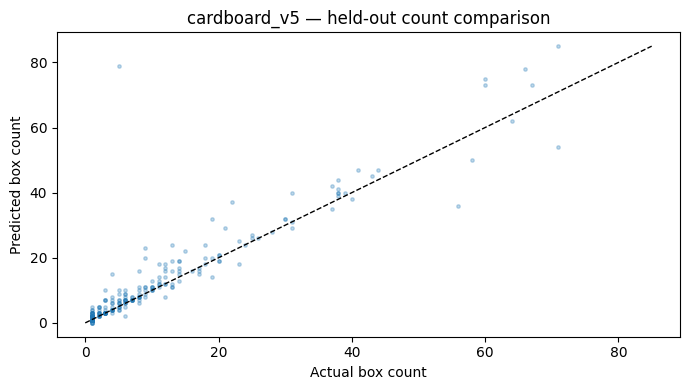

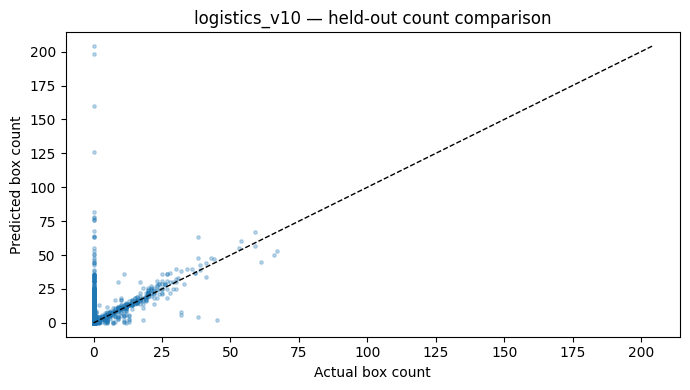

In [16]:
if RUN_FINAL_TEST and count_rows:
    for dataset in DATASETS:
        subset=counts[counts.dataset==dataset]
        fig,ax=plt.subplots(figsize=(7,4))
        ax.scatter(subset.actual_count,subset.predicted_count,s=6,alpha=.28)
        lim=max(1,int(max(subset.actual_count.max(),subset.predicted_count.max())))
        ax.plot([0,lim],[0,lim],ls='--',color='black',lw=1)
        ax.set(xlabel='Actual box count',ylabel='Predicted box count',title=f'{dataset} — held-out count comparison')
        fig.tight_layout();fig.savefig(OUT/f'{dataset}_count_scatter.png',dpi=150);plt.show()

In [17]:
research_report={
    'project':'BoxCount Vision / Day 28','generated_at_utc':datetime.now(timezone.utc).isoformat(),
    'task':'single class box detection and count regression-by-detection',
    'dataset_root':str(INPUT_ROOT),'seed':SEED,
    'split_policy':'preserve source chronological-or-original train/valid/test splits (original split provenance must be reviewed)',
    'selection_metric':'validation mAP@50:95 only',
    'selection':valdf.to_dict('records'),
    'champion':str(champ.experiment),
    'heldout_detection':heldout,
    'heldout_counting':scores.to_dict('records') if RUN_FINAL_TEST and count_rows else [],
    'limitations':['Kaggle source semantics and license require independent verification','Original splits may not be independent at sequence/source level','Exact hash audit is not near-duplicate proof','Logistics negatives may have omitted box annotations','Counting metrics are threshold-specific','No deployment, operational safety or generalization guarantee'],
    'deployment_ready':False,
}
(OUT/'research_report.json').write_text(json.dumps(research_report,indent=2,default=str),encoding='utf-8')
shutil.copy2(champ_path,OUT/'boxcount_champion.pt')
(OUT/'README.md').write_text('BoxCount Vision Day 28 experimental artifacts. All metrics originate from executed notebook cells. See research_report.json. Not production validated.\n',encoding='utf-8')
archive=shutil.make_archive(str(WORK/'BoxCount_Day28_Results'),'zip',root_dir=OUT)
print('RESULTS ZIP:',archive,'SIZE MiB:',round(Path(archive).stat().st_size/2**20,2))
print('Saved artifacts:',sorted(p.name for p in OUT.iterdir()))

RESULTS ZIP: /kaggle/working/boxcount_day28/BoxCount_Day28_Results.zip SIZE MiB: 8.02
Saved artifacts: ['A_train_selection.csv', 'A_valid_selection.csv', 'B_train_selection.csv', 'B_valid_selection.csv', 'README.md', 'boxcount_champion.pt', 'cardboard_v5_annotation_gallery.png', 'cardboard_v5_count_scatter.png', 'dataset_audit_clean.json', 'dataset_inventory.csv', 'filename_audit.json', 'final_heldout_detection_metrics.csv', 'heldout_count_metrics.csv', 'heldout_count_predictions.csv', 'invalid_annotation_audit.csv', 'logistics_v10_annotation_gallery.png', 'logistics_v10_count_scatter.png', 'near_duplicate_candidates_sample.csv', 'research_report.json', 'sha_leakage_audit.json', 'validation_model_selection.csv']


## 14 — Interpretation and reproducibility checklist

- Confirm source licensing before public redistribution.
- Inspect original split provenance: random Roboflow splits may contain near-identical frames/derived augmentations across train/validation/test.
- Review `near_duplicate_candidates_sample.csv`; sampled dHash is a screening tool, **not** a guarantee.
- Audit per-source positives/negatives. Empty Logistics labels mean *no box annotated* and may contain missed positives.
- Report source-specific detection mAP@50:95 and count MAE/RMSE. Do not merge domains' metrics into one unqualified accuracy.
- Select best model using validation data only. Test sets remain untouched for hyperparameter decisions.
- `boxcount_champion.pt` is for research; do not imply warehouse-ready accuracy, live tracking or safety guarantees.
- Kaggle GPU availability, image volume, package versions and source splits affect reproducibility. Keep exported `run_config`, `.csv`, plots and original dataset provenance.